### Cell 1 — Import thư viện & cấu hình

In [2]:
!pip install -q torch-geometric

In [3]:
import os, re, sys, glob, json, time, warnings, importlib
import numpy as np
import pandas as pd
import joblib

warnings.filterwarnings("ignore")

INPUT_ROOT  = "/kaggle/input/datasets/kimngn2005/trafficlabelling-model"
METRICS_DIR = "/kaggle/input/datasets/kimngn2005/preprocess-khang"
WORK_DIR    = "/kaggle/working"
OUT_DIR     = f"{WORK_DIR}/processed"   # dữ liệu đã xử lý (bàn giao cho Người B)
MODEL_DIR   = f"{WORK_DIR}/models"      # mô hình baseline
RESULT_DIR  = f"{WORK_DIR}/results"     # kết quả đánh giá

for d in (OUT_DIR, MODEL_DIR, RESULT_DIR):
    os.makedirs(d, exist_ok=True)

sys.path.insert(0, WORK_DIR)
sys.path.insert(0, METRICS_DIR)         # trỏ thẳng tới chỗ chứa metrics.py của bạn

SEED = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15       # Test = 0.15 còn lại (chia theo thứ tự thời gian)

def norm(c):
    return re.sub(r"[^a-z0-9]", "", str(c).lower())

# Tên cột chuẩn -> các biến thể tên có thể gặp ở các phiên bản CIC-IDS2017
ALIASES = {
    "flow_id":   ["flowid"],
    "src_ip":    ["sourceip", "srcip"],
    "dst_ip":    ["destinationip", "dstip"],
    "src_port":  ["sourceport", "srcport"],
    "dst_port":  ["destinationport", "dstport"],
    "timestamp": ["timestamp"],
    "label":     ["label"],
}

import metrics
print("pandas", pd.__version__, "| numpy", np.__version__, "| metrics loaded OK!")

pandas 2.3.3 | numpy 2.1.3 | metrics loaded OK!


### Cell 2 — Tìm file & kiểm tra dataset có đủ cột cần thiết

In [4]:
files = sorted(glob.glob(f"{INPUT_ROOT}/**/*.parquet", recursive=True))
if not files:
    files = sorted(glob.glob(f"{INPUT_ROOT}/**/*.csv", recursive=True))
assert files, "Không thấy file .parquet/.csv trong /kaggle/input -> kiểm tra lại bước Add Input."

print(f"Tìm thấy {len(files)} file:")
for f in files:
    print(f"  {os.path.getsize(f)/1e6:8.1f} MB  {f}")

def read_one(f):
    if f.endswith(".parquet"):
        d = pd.read_parquet(f)
    else:
        d = pd.read_csv(f, encoding="latin-1", low_memory=False)
    d.columns = [str(c).strip() for c in d.columns]
    return d

sample = read_one(files[0])
print(f"\nFile đầu tiên: {os.path.basename(files[0])} -> {sample.shape[0]:,} dòng, {sample.shape[1]} cột")
print(list(sample.columns))

cols_norm = {norm(c) for c in sample.columns}
print("\nKiểm tra các cột bắt buộc:")
for need, key in [("Timestamp (bắt buộc để chia theo thời gian)", "timestamp"),
                  ("Source IP (cần cho đồ thị của Người B)", "src_ip"),
                  ("Destination IP (cần cho đồ thị của Người B)", "dst_ip"),
                  ("Label", "label")]:
    ok = any(n in cols_norm for n in ALIASES[key])
    print(f"  [{'OK' if ok else 'THIẾU'}] {need}")

Tìm thấy 8 file:
      96.1 MB  /kaggle/input/datasets/kimngn2005/trafficlabelling-model/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
     101.9 MB  /kaggle/input/datasets/kimngn2005/trafficlabelling-model/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
      75.4 MB  /kaggle/input/datasets/kimngn2005/trafficlabelling-model/Friday-WorkingHours-Morning.pcap_ISCX.csv
     268.6 MB  /kaggle/input/datasets/kimngn2005/trafficlabelling-model/Monday-WorkingHours.pcap_ISCX.csv
     108.7 MB  /kaggle/input/datasets/kimngn2005/trafficlabelling-model/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
      92.0 MB  /kaggle/input/datasets/kimngn2005/trafficlabelling-model/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
     174.7 MB  /kaggle/input/datasets/kimngn2005/trafficlabelling-model/Tuesday-WorkingHours.pcap_ISCX.csv
     285.6 MB  /kaggle/input/datasets/kimngn2005/trafficlabelling-model/Wednesday-workingHours.pcap_ISCX.csv

File đầu tiên: Friday-WorkingHours-Aftern

### Cell 3 — Tải & gộp toàn bộ file

In [5]:
parts = []
for f in files:
    d = read_one(f)
    d["source_file"] = os.path.basename(f)
    print(f"{os.path.basename(f):60s} {d.shape[0]:>10,} dòng")
    parts.append(d)
df = pd.concat(parts, ignore_index=True, sort=False)
del parts
print(f"\nTổng: {df.shape[0]:,} dòng x {df.shape[1]} cột | RAM ~ {df.memory_usage(deep=True).sum()/1e9:.2f} GB")

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                225,745 dòng
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv            286,467 dòng
Friday-WorkingHours-Morning.pcap_ISCX.csv                       191,033 dòng
Monday-WorkingHours.pcap_ISCX.csv                               529,918 dòng
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv     288,602 dòng
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv          458,968 dòng
Tuesday-WorkingHours.pcap_ISCX.csv                              445,909 dòng
Wednesday-workingHours.pcap_ISCX.csv                            692,703 dòng

Tổng: 3,119,345 dòng x 86 cột | RAM ~ 3.26 GB


### Cell 4 — Xác định cột, chuẩn hóa nhãn và Timestamp

In [6]:
# --- 4.1 Xác định các cột định danh / thời gian / nhãn ---
colmap = {}
for canon, names in ALIASES.items():
    for c in df.columns:
        if norm(c) in names:
            colmap[canon] = c
            break
print("Ánh xạ cột:", colmap)

assert "timestamp" in colmap, ("Dataset KHÔNG có cột Timestamp -> không thể chia theo thời gian đúng yêu cầu. "
                               "Cần dùng bản CIC-IDS2017 có metadata (xem hướng dẫn ở câu 1).")
assert "label" in colmap, "Không tìm thấy cột Label."
if "src_ip" not in colmap or "dst_ip" not in colmap:
    print("CẢNH BÁO: thiếu Source/Destination IP -> Người B sẽ không dựng được đồ thị Node = IP.")

# --- 4.2 Chuẩn hóa nhãn ---
LABEL, TS = colmap["label"], colmap["timestamp"]
df = df.dropna(subset=[LABEL, TS]).reset_index(drop=True)

def clean_label(s):
    s = re.sub(r"\s*[^\x20-\x7E]+\s*", " - ", str(s))   # ký tự lỗi mã hóa ở 'Web Attack � Brute Force'
    return re.sub(r"\s+", " ", s).strip()

label_map = {v: clean_label(v) for v in df[LABEL].unique()}
df["label_multi"] = df[LABEL].map(label_map)
df["label_bin"] = (df["label_multi"].str.lower() != "benign").astype("int8")   # 0 = Normal, 1 = Attack
print("\nPhân bố nhãn (toàn bộ):")
print(df["label_multi"].value_counts().to_string())

# --- 4.3 Chuẩn hóa Timestamp ---
if not pd.api.types.is_datetime64_any_dtype(df[TS]):
    try:
        ts = pd.to_datetime(df[TS], errors="coerce", format="mixed", dayfirst = True)
    except (ValueError, TypeError):
        ts = pd.to_datetime(df[TS], errors="coerce", dayfirst = True)
    # Bản CSV gốc ghi giờ dạng 12h không có AM/PM: các giờ 1..7 thực chất là 13..19 giờ
    ts = ts.where(~ts.dt.hour.between(1, 7), ts + pd.Timedelta(hours=12))
    df[TS] = ts
n_bad = int(df[TS].isna().sum())
if n_bad:
    print(f"Bỏ {n_bad:,} dòng có Timestamp không đọc được")
    df = df.dropna(subset=[TS]).reset_index(drop=True)

chk = df.groupby("source_file")[TS].agg(["min", "max"])
chk["giờ_min"] = df.groupby("source_file")[TS].apply(lambda s: s.dt.hour.min())
chk["giờ_max"] = df.groupby("source_file")[TS].apply(lambda s: s.dt.hour.max())
print("\nKhoảng thời gian từng file (kỳ vọng: 03/07 -> 07/07/2017, giờ ~ 8..17):")
print(chk.to_string())

Ánh xạ cột: {'flow_id': 'Flow ID', 'src_ip': 'Source IP', 'dst_ip': 'Destination IP', 'src_port': 'Source Port', 'dst_port': 'Destination Port', 'timestamp': 'Timestamp', 'label': 'Label'}

Phân bố nhãn (toàn bộ):
label_multi
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack - Brute Force         1507
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11

Khoảng thời gian từng file (kỳ vọng: 03/07 -> 07/07/2017, giờ ~ 8..17):
                                                                            min                 max  giờ_min  giờ_max
source_file  

### Cell 5 — Làm sạch: loại cột định danh, xử lý Inf/NaN, loại dòng trùng

In [7]:
# --- 5.1 Xác định cột đặc trưng (loại bỏ cột định danh) ---
# Giữ lại 'Destination Port' và 'Protocol' làm đặc trưng; bỏ Flow ID, IP, Source Port (cổng tạm thời), Timestamp, nhãn.
drop_as_feature = {colmap[k] for k in colmap if k != "dst_port"}
drop_as_feature |= {"label_multi", "label_bin", "source_file"}
feature_cols = [c for c in df.columns if c not in drop_as_feature]

# Cột trùng lặp (vd. 'Fwd Header Length.1' của bản CSV gốc)
dups = [c for c in feature_cols if c.endswith(".1") and c[:-2] in feature_cols and df[c].equals(df[c[:-2]])]
feature_cols = [c for c in feature_cols if c not in dups]
print("Cột trùng bị loại:", dups)

# --- 5.2 Ép kiểu số, đổi Inf -> NaN, hạ về float32 ---
report = []
for c in feature_cols:
    s = pd.to_numeric(df[c], errors="coerce")
    n_inf = int(np.isinf(s).sum())
    s = s.replace([np.inf, -np.inf], np.nan).astype("float32")
    s = s.replace([np.inf, -np.inf], np.nan)            # phòng trường hợp tràn khi ép sang float32
    n_nan = int(s.isna().sum())
    if n_inf or n_nan:
        report.append((c, n_inf, n_nan))
    df[c] = s
if report:
    print("\nCột có Inf/NaN (số Inf, số NaN sau khi đổi Inf -> NaN):")
    for c, i, n in report:
        print(f"  {c:35s} inf={i:>8,}  nan={n:>8,}")

all_nan = [c for c in feature_cols if df[c].isna().all()]
feature_cols = [c for c in feature_cols if c not in all_nan]
print("Cột toàn NaN bị loại:", all_nan)

# --- 5.3 Loại bản ghi trùng lặp hoàn toàn ---
before = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "source_file"]).reset_index(drop=True)
print(f"\nBỏ {before - len(df):,} dòng trùng lặp hoàn toàn -> còn {len(df):,} dòng, {len(feature_cols)} đặc trưng")
# NaN còn lại sẽ được điền bằng median của tập TRAIN ở bước 7 (tránh rò rỉ thông tin).

Cột trùng bị loại: ['Fwd Header Length.1']

Cột có Inf/NaN (số Inf, số NaN sau khi đổi Inf -> NaN):
  Flow Bytes/s                        inf=   1,509  nan=   2,867
  Flow Packets/s                      inf=   2,867  nan=   2,867
Cột toàn NaN bị loại: []

Bỏ 203 dòng trùng lặp hoàn toàn -> còn 2,830,540 dòng, 78 đặc trưng


### Cell 6 — Chia Train / Validation / Test theo thời gian (70 / 15 / 15)

In [8]:
# SPLIT_MODE (mọi chế độ đều giữ thứ tự thời gian, KHÔNG xáo trộn):
#   "per_file_label": với mỗi (file, loại nhãn), sắp xếp theo thời gian rồi lấy 70% đầu -> Train, 15% kế -> Val, 15% cuối -> Test
#   "per_file"      : với mỗi file, chia 70/15/15 theo thời gian (loại tấn công nằm ở khung giờ sáng thường rơi hết vào Train)
#   "global"        : sắp xếp toàn bộ tuần theo thời gian rồi cắt 70/15/15 (nhiều loại tấn công chỉ xuất hiện ở Val/Test)
SPLIT_MODE = "per_file_label"

df = df.sort_values(TS, kind="mergesort").reset_index(drop=True)
n = len(df)
ts_all = df[TS]
assert ts_all.is_monotonic_increasing

if SPLIT_MODE == "global":
    groups = {"global": np.arange(n)}
elif SPLIT_MODE == "per_file":
    groups = dict(df.groupby("source_file").indices)
elif SPLIT_MODE == "per_file_label":
    groups = {f"{f} | {l}": idx for (f, l), idx in df.groupby(["source_file", "label_multi"]).indices.items()}
else:
    raise ValueError("SPLIT_MODE phải là 'per_file_label', 'per_file' hoặc 'global'")

is_train = np.zeros(n, dtype=bool)
is_val = np.zeros(n, dtype=bool)
is_test = np.zeros(n, dtype=bool)
split_boundaries = {}
for gname, idx in groups.items():          # idx: vị trí các dòng của nhóm, đã theo thứ tự thời gian
    k = len(idx)
    i1, i2 = int(k * TRAIN_FRAC), int(k * (TRAIN_FRAC + VAL_FRAC))
    is_train[idx[:i1]] = True
    is_val[idx[i1:i2]] = True
    is_test[idx[i2:]] = True
    split_boundaries[gname] = {"n": int(k), "val_starts": str(ts_all.iloc[idx[i1]]), "test_starts": str(ts_all.iloc[idx[i2]])}

assert is_train.sum() + is_val.sum() + is_test.sum() == n
assert not (is_train & is_val).any() and not (is_train & is_test).any() and not (is_val & is_test).any()
print("SPLIT_MODE =", SPLIT_MODE, "| số nhóm:", len(groups))

rows = []
for name, m in [("train", is_train), ("val", is_val), ("test", is_test)]:
    s = df.loc[m]
    rows.append({"split": name, "n": len(s), "from": s[TS].min(), "to": s[TS].max(),
                 "n_attack": int(s["label_bin"].sum()), "attack_%": round(100 * s["label_bin"].mean(), 2)})
print(pd.DataFrame(rows).to_string(index=False))

split_name = np.select([is_train, is_val, is_test], ["1_train", "2_val", "3_test"], default="")
ct = pd.crosstab(df["label_multi"], split_name)
print("\nSố mẫu theo loại nhãn và theo tập:")
print(ct.to_string())

all_types = set(df["label_multi"])
miss_test = sorted(all_types - set(df.loc[is_test, "label_multi"]))
unseen = sorted(set(df.loc[is_val | is_test, "label_multi"]) - set(df.loc[is_train, "label_multi"]))
print("\nLoại nhãn KHÔNG có trong Test :", miss_test if miss_test else "không có")
print("Loại nhãn có ở Val/Test nhưng không có ở Train:", unseen if unseen else "không có")

for name, m in [("train", is_train), ("val", is_val), ("test", is_test)]:
    assert df.loc[m, "label_bin"].nunique() == 2, f"Tập {name} chỉ có 1 lớp -> cần xem lại tỉ lệ chia."

SPLIT_MODE = per_file_label | số nhóm: 22
split       n                from                  to  n_attack  attack_%
train 1981368 2017-07-03 08:55:58 2017-07-07 16:15:00    390345      19.7
  val  424581 2017-07-03 14:06:20 2017-07-07 16:38:00     83647      19.7
 test  424591 2017-07-03 15:47:50 2017-07-07 17:02:00     83653      19.7

Số mẫu theo loại nhãn và theo tập:
col_0                       1_train   2_val  3_test
label_multi                                        
BENIGN                      1591023  340934  340938
Bot                            1376     295     295
DDoS                          89618   19204   19205
DoS GoldenEye                  7205    1544    1544
DoS Hulk                     161750   34661   34661
DoS Slowhttptest               3849     825     825
DoS slowloris                  4057     869     870
FTP-Patator                    5556    1191    1191
Heartbleed                        7       2       2
Infiltration                     25       5       6
Po

### Cell 7 — Điền NaN & chuẩn hóa (StandardScaler chỉ fit trên Train)

In [9]:
from sklearn.preprocessing import StandardScaler

# --- 7.1 Median để điền NaN: chỉ tính trên TRAIN ---
medians = df.loc[is_train, feature_cols].median()
tr_filled = df.loc[is_train, feature_cols].fillna(medians)

# --- 7.2 Loại đặc trưng hằng số (độ lệch chuẩn = 0 trên TRAIN) ---
std_tr = tr_filled.std()
const_cols = std_tr[(std_tr == 0) | std_tr.isna()].index.tolist()
final_features = [c for c in feature_cols if c not in const_cols]
print(f"Loại {len(const_cols)} đặc trưng hằng số: {const_cols}")
print(f"Số đặc trưng cuối cùng: {len(final_features)}")

# --- 7.3 Scaler: FIT chỉ trên TRAIN, TRANSFORM cho Train/Val/Test ---
scaler = StandardScaler()
scaler.fit(tr_filled[final_features])
del tr_filled

def transform(mask):
    part = df.loc[mask, final_features].fillna(medians[final_features])
    return scaler.transform(part).astype("float32")

X = {"train": transform(is_train), "val": transform(is_val), "test": transform(is_test)}
masks = {"train": is_train, "val": is_val, "test": is_test}

for k, v in X.items():
    assert np.isfinite(v).all(), f"Còn NaN/Inf ở tập {k}"
print("\nTrain sau chuẩn hóa: mean ~", float(np.abs(X['train'].mean(axis=0)).max()),
      "| std ~", float(X['train'].std(axis=0).mean()))
print({k: v.shape for k, v in X.items()})

Loại 8 đặc trưng hằng số: ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Số đặc trưng cuối cùng: 70

Train sau chuẩn hóa: mean ~ 6.77700171536344e-08 | std ~ 1.0
{'train': (1981368, 70), 'val': (424581, 70), 'test': (424591, 70)}


### Cell 8 — Lưu dữ liệu đã xử lý & cấu hình (phục vụ Handover 1)

In [10]:
meta_cols = {k: colmap[k] for k in ["flow_id", "src_ip", "dst_ip", "src_port", "dst_port", "timestamp"] if k in colmap}
rename = {v: k for k, v in meta_cols.items()}

for name in ["train", "val", "test"]:
    # đặc trưng đã chuẩn hóa
    pd.DataFrame(X[name], columns=final_features).to_parquet(f"{OUT_DIR}/{name}_features.parquet", index=False)
    # metadata + nhãn (cùng thứ tự dòng với file features) -> Người B dùng để dựng đồ thị
    meta = df.loc[masks[name], list(meta_cols.values()) + ["label_multi", "label_bin", "source_file"]]
    meta = meta.rename(columns=rename).reset_index(drop=True)
    meta.to_parquet(f"{OUT_DIR}/{name}_meta.parquet", index=False)

# Bộ tiền xử lý: dùng lại y hệt cho dữ liệu Streaming (Inf->NaN, fillna(medians), scaler.transform)
joblib.dump({"feature_cols": final_features, "medians": medians[final_features],
             "scaler": scaler}, f"{OUT_DIR}/preprocessor.joblib")

config = {
    "split": {"train_frac": TRAIN_FRAC, "val_frac": VAL_FRAC, "test_frac": round(1 - TRAIN_FRAC - VAL_FRAC, 4),
              "mode": SPLIT_MODE, "boundaries": split_boundaries,
              "n_train": int(is_train.sum()), "n_val": int(is_val.sum()), "n_test": int(is_test.sum())},
    "label_binary": {"0": "Normal (Benign)", "1": "Attack"},
    "label_multi_classes": sorted(df["label_multi"].unique().tolist()),
    "meta_columns": list(meta_cols.keys()),
    "n_features": len(final_features),
    "features": final_features,
    "dropped_constant_features": const_cols,
    "scaler": "StandardScaler (fit trên Train)",
    "nan_strategy": "Inf->NaN; điền median của Train",
    "seed": SEED,
}
with open(f"{OUT_DIR}/config.json", "w", encoding="utf-8") as fh:
    json.dump(config, fh, ensure_ascii=False, indent=2)

print("Đã lưu:")
for f in sorted(os.listdir(OUT_DIR)):
    print(f"  {os.path.getsize(os.path.join(OUT_DIR, f))/1e6:8.1f} MB  {f}")

Đã lưu:
       0.0 MB  config.json
       0.0 MB  preprocessor.joblib
      37.9 MB  test_features.parquet
       6.2 MB  test_meta.parquet
     171.7 MB  train_features.parquet
      27.7 MB  train_meta.parquet
      37.0 MB  val_features.parquet
       6.1 MB  val_meta.parquet


### Cell 9 — Viết file metrics.py (F1, Recall, Confusion Matrix)

In [11]:
%%writefile /kaggle/working/metrics.py
"""
metrics.py - Thư viện đánh giá dùng chung cho cả nhóm (RF, XGBoost, GraphSAGE, MLP).

Quy ước nhãn nhị phân: 0 = Normal (Benign), 1 = Attack (lớp dương).
Các chỉ số chính: F1-score, Recall, Confusion Matrix. Bổ sung: Precision, Macro-F1, FPR, FNR.

Cách dùng:
    import metrics
    res = metrics.evaluate_and_save("random_forest", "test", y_true, y_pred, y_score,
                                    label_multi=label_multi, out_dir="results")
"""
import json
import os

import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)

NORMAL, ATTACK = 0, 1
CLASS_NAMES = ["Normal", "Attack"]


def compute_metrics(y_true, y_pred, y_score=None):
    """Chỉ số cho bài toán nhị phân Normal/Attack. Trả về dict (có thể ghi JSON)."""
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[NORMAL, ATTACK])
    tn, fp, fn, tp = (int(v) for v in cm.ravel())
    res = {
        "n_samples": int(len(y_true)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, pos_label=ATTACK, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, pos_label=ATTACK, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, pos_label=ATTACK, zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", labels=[NORMAL, ATTACK], zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", labels=[NORMAL, ATTACK], zero_division=0)),
        "fpr": float(fp / (fp + tn)) if (fp + tn) else 0.0,   # Normal bị báo nhầm là Attack
        "fnr": float(fn / (fn + tp)) if (fn + tp) else 0.0,   # Attack bị bỏ sót
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "confusion_matrix": cm.tolist(),                      # [[TN, FP], [FN, TP]]
    }
    if y_score is not None and len(np.unique(y_true)) == 2:
        res["roc_auc"] = float(roc_auc_score(y_true, y_score))
        res["pr_auc"] = float(average_precision_score(y_true, y_score))
    return res


def compute_multiclass_metrics(y_true, y_pred, labels=None):
    """Chỉ số đa lớp (dùng cho phân tích lỗi theo loại tấn công). Nhãn là chuỗi hoặc số."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if labels is None:
        labels = sorted(set(y_true) | set(y_pred))
    p = precision_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    r = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    f = f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    support = pd.Series(y_true).value_counts().reindex(labels).fillna(0).astype(int).to_numpy()
    per_class = pd.DataFrame({"class": labels, "precision": p, "recall": r, "f1": f, "support": support})
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        "per_class": per_class,
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels),
        "labels": list(labels),
    }


def detection_rate_by_type(label_multi, y_pred):
    """Với mỗi loại nhãn gốc: tỉ lệ bị dự đoán là Attack.
    Dòng Benign chính là False Positive Rate; các dòng tấn công chính là Recall theo từng loại."""
    d = pd.DataFrame({"label": np.asarray(label_multi), "pred_attack": np.asarray(y_pred).astype(int)})
    g = d.groupby("label")["pred_attack"].agg(n="size", predicted_attack="sum")
    g["rate_predicted_attack"] = g["predicted_attack"] / g["n"]
    return g.reset_index().sort_values("n", ascending=False).reset_index(drop=True)


def plot_confusion_matrix(cm, class_names=None, title="Confusion Matrix", normalize=False, save_path=None, show=True):
    import matplotlib
    import matplotlib.pyplot as plt
    cm = np.asarray(cm)
    class_names = class_names or CLASS_NAMES
    data = cm.astype(float)
    if normalize:
        data = data / np.maximum(data.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(5, 4.2))
    im = ax.imshow(data, cmap="Blues")
    ax.set_xticks(range(len(class_names)), labels=class_names)
    ax.set_yticks(range(len(class_names)), labels=class_names)
    ax.set_xlabel("Dự đoán (Predicted)")
    ax.set_ylabel("Thực tế (Actual)")
    ax.set_title(title)
    thresh = data.max() / 2 if data.max() > 0 else 0.5
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            txt = f"{data[i, j]:.2%}" if normalize else f"{int(cm[i, j]):,}"
            ax.text(j, i, txt, ha="center", va="center", color="white" if data[i, j] > thresh else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
    if show:
        plt.show()
    plt.close(fig)


def evaluate_and_save(model_name, split_name, y_true, y_pred, y_score=None, label_multi=None,
                      out_dir="results", verbose=True):
    """Tính chỉ số, in kết quả, lưu JSON + ảnh Confusion Matrix (+ CSV theo loại tấn công nếu có label_multi)."""
    os.makedirs(out_dir, exist_ok=True)
    tag = f"{model_name}_{split_name}"
    res = compute_metrics(y_true, y_pred, y_score)
    res.update({"model": model_name, "split": split_name})
    with open(os.path.join(out_dir, f"{tag}_metrics.json"), "w", encoding="utf-8") as fh:
        json.dump(res, fh, ensure_ascii=False, indent=2)
    plot_confusion_matrix(res["confusion_matrix"], title=f"{model_name} - {split_name}",
                          save_path=os.path.join(out_dir, f"{tag}_confusion_matrix.png"), show=verbose)
    if label_multi is not None:
        detection_rate_by_type(label_multi, y_pred).to_csv(
            os.path.join(out_dir, f"{tag}_detection_by_type.csv"), index=False)
    if verbose:
        print(f"[{tag}] F1={res['f1']:.4f} | Recall={res['recall']:.4f} | Precision={res['precision']:.4f} | "
              f"Macro-F1={res['macro_f1']:.4f} | FPR={res['fpr']:.4f} | CM(TN,FP,FN,TP)="
              f"({res['tn']:,}, {res['fp']:,}, {res['fn']:,}, {res['tp']:,})")
    return res

Writing /kaggle/working/metrics.py


### Cell 10 — Nạp lại dữ liệu đã lưu (kiểm tra đúng thứ Người B sẽ nhận)

In [12]:
import metrics
importlib.reload(metrics)

def load_split(name):
    X_ = pd.read_parquet(f"{OUT_DIR}/{name}_features.parquet")
    m_ = pd.read_parquet(f"{OUT_DIR}/{name}_meta.parquet")
    return X_, m_["label_bin"].to_numpy(), m_["label_multi"].to_numpy()

Xtr, ytr, ltr = load_split("train")
Xva, yva, lva = load_split("val")
Xte, yte, lte = load_split("test")
print("Train/Val/Test:", Xtr.shape, Xva.shape, Xte.shape)
print("Tỉ lệ Attack - Train/Val/Test:", ytr.mean().round(4), yva.mean().round(4), yte.mean().round(4))

Train/Val/Test: (1981368, 70) (424581, 70) (424591, 70)
Tỉ lệ Attack - Train/Val/Test: 0.197 0.197 0.197


In [13]:
import pandas as pd

# Liệt kê tất cả biến DataFrame và list cột đang có
dfs = {
    k: v.shape for k, v in globals().items() if isinstance(v, pd.DataFrame)
}
lists = {
    k: len(v)
    for k, v in globals().items()
    if isinstance(v, list) and len(v) in [70, 78]
}
print("Các biến DataFrame:", dfs)
print("Các biến danh sách cột:", lists)

Các biến DataFrame: {'d': (692703, 86), 'sample': (225745, 85), 'df': (2830540, 88), 'chk': (8, 4), 's': (424591, 88), 'ct': (15, 3), 'meta': (424591, 9), 'Xtr': (1981368, 70), 'Xva': (424581, 70), 'Xte': (424591, 70)}
Các biến danh sách cột: {'feature_cols': 78, 'final_features': 70}


### Cell 13: Cài PyTorch Geometric & Viết hàm Graph Builder (Biến bảng thành đồ thị theo cửa sổ)

In [14]:
import os
import numpy as np
import pandas as pd
import torch
from torch_geometric.data import Data
from torch_geometric.utils import scatter

WINDOW_SIZE = 5000
_feat_cols = final_features  # 70 đặc trưng

# 1. Tìm đúng thư mục chứa file parquet của Khang
DATA_DIR = (
    "/kaggle/working/processed"
    if os.path.exists("/kaggle/working/processed/test_meta.parquet")
    else "/kaggle/input/preprocess-khang"
)

Xtr = pd.read_parquet(f"{DATA_DIR}/train_features.parquet")
Xva = pd.read_parquet(f"{DATA_DIR}/val_features.parquet")
Xte = pd.read_parquet(f"{DATA_DIR}/test_features.parquet")

meta_tr = pd.read_parquet(f"{DATA_DIR}/train_meta.parquet")
meta_va = pd.read_parquet(f"{DATA_DIR}/val_meta.parquet")
meta_te = pd.read_parquet(f"{DATA_DIR}/test_meta.parquet")

# Kiểm tra tính toàn vẹn 100% giữa đặc trưng và metadata
assert (
    len(Xtr) == len(meta_tr)
    and len(Xva) == len(meta_va)
    and len(Xte) == len(meta_te)
)
print("Đã nạp chuẩn xác bộ features và meta từ:", DATA_DIR)


# 2. Hàm dựng đồ thị đồng bộ tuyệt đối giữa X, y và meta
def build_window_graphs(X_split, df_meta, feature_cols, window_size=5000):
    # Chuẩn hóa tên cột IP & Timestamp (hỗ trợ cả tên gốc và tên đã đổi của Khang)
    ts_col = "timestamp" if "timestamp" in df_meta.columns else "Timestamp"
    src_col = "src_ip" if "src_ip" in df_meta.columns else "Source IP"
    dst_col = "dst_ip" if "dst_ip" in df_meta.columns else "Destination IP"

    y_arr = df_meta["label_bin"].to_numpy(dtype=np.float32)
    X_arr = X_split[feature_cols].to_numpy(dtype=np.float32)

    # Sắp xếp ổn định (mergesort) theo Timestamp giống hệt pipeline Chương 4
    order = np.argsort(df_meta[ts_col].to_numpy(), kind="mergesort")
    df_meta_sorted = df_meta.iloc[order].reset_index(drop=True)
    X_arr = X_arr[order]
    y_arr = y_arr[order]

    graphs = []
    num_rows = len(df_meta_sorted)
    for start in range(0, num_rows, window_size):
        end = min(start + window_size, num_rows)
        if end - start < 2:
            continue

        chunk_meta = df_meta_sorted.iloc[start:end]
        chunk_X = X_arr[start:end]
        chunk_y = y_arr[start:end]

        s_ips = chunk_meta[src_col].astype(str)
        d_ips = chunk_meta[dst_col].astype(str)
        ips = pd.Index(pd.concat([s_ips, d_ips]).unique())
        num_nodes = len(ips)

        src_t = torch.tensor(ips.get_indexer(s_ips), dtype=torch.long)
        dst_t = torch.tensor(ips.get_indexer(d_ips), dtype=torch.long)
        edge_index = torch.stack([src_t, dst_t], dim=0)

        edge_attr = torch.tensor(chunk_X, dtype=torch.float32)
        y = torch.tensor(chunk_y, dtype=torch.float32)

        edge_ends = torch.cat([src_t, dst_t], dim=0)
        edge_feats_dup = torch.cat([edge_attr, edge_attr], dim=0)

        node_mean = scatter(
            edge_feats_dup,
            edge_ends,
            dim=0,
            dim_size=num_nodes,
            reduce="mean",
        )
        node_max = scatter(
            edge_feats_dup, edge_ends, dim=0, dim_size=num_nodes, reduce="max"
        )
        node_x = torch.cat([node_mean, node_max], dim=-1)  # 140 chiều

        graphs.append(
            Data(x=node_x, edge_index=edge_index, edge_attr=edge_attr, y=y)
        )

    return graphs


train_graphs = build_window_graphs(Xtr, meta_tr, _feat_cols, WINDOW_SIZE)
val_graphs = build_window_graphs(Xva, meta_va, _feat_cols, WINDOW_SIZE)
test_graphs = build_window_graphs(Xte, meta_te, _feat_cols, WINDOW_SIZE)

print(
    f"Số đồ thị -> Train: {len(train_graphs)} | Val: {len(val_graphs)} | Test:"
    f" {len(test_graphs)}"
)

Đã nạp chuẩn xác bộ features và meta từ: /kaggle/working/processed
Số đồ thị -> Train: 397 | Val: 85 | Test: 85


### Cell 14: Kiến trúc E-GraphSAGE & Huấn luyện (Lưu checkpoint.pth)

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import scatter

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NODE_DIM = len(_feat_cols) * 2  # 140 (70 mean + 70 max)
EDGE_DIM = len(_feat_cols)  # 70


class EGraphSAGEConv(nn.Module):

    def __init__(self, node_in_dim, edge_dim, out_dim):
        super().__init__()
        self.sage = SAGEConv(node_in_dim + edge_dim, out_dim, aggr="max")
        self.bn = nn.BatchNorm1d(out_dim)
        self.act = nn.LeakyReLU(0.2)

    def forward(self, x, edge_index, edge_attr):
        src, dst = edge_index
        num_nodes = x.size(0)

        edge_ends = torch.cat([src, dst], dim=0)
        edge_feats = torch.cat([edge_attr, edge_attr], dim=0)
        agg_edge = scatter(
            edge_feats, edge_ends, dim=0, dim_size=num_nodes, reduce="mean"
        )

        x_aug = torch.cat([x, agg_edge], dim=-1)
        out = self.sage(x_aug, edge_index)
        out = self.bn(out)
        return self.act(out)


class EGraphSAGEModel(nn.Module):

    def __init__(self, node_dim, edge_dim, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.conv1 = EGraphSAGEConv(node_dim, edge_dim, hidden_dim)
        self.conv2 = EGraphSAGEConv(hidden_dim, edge_dim, hidden_dim)

        self.edge_enc = nn.Sequential(
            nn.Linear(edge_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 3, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, data):
        x = torch.clamp(data.x, -25.0, 25.0)
        edge_attr = torch.clamp(data.edge_attr, -25.0, 25.0)
        edge_index = data.edge_index

        h = self.conv1(x, edge_index, edge_attr)
        h = self.conv2(h, edge_index, edge_attr)

        src, dst = edge_index
        e_emb = self.edge_enc(edge_attr)

        out = torch.cat([h[src], h[dst], e_emb], dim=-1)
        return self.classifier(out).squeeze(-1)


train_loader = DataLoader(train_graphs, batch_size=8, shuffle=True)
val_loader = DataLoader(val_graphs, batch_size=8, shuffle=False)
test_loader = DataLoader(test_graphs, batch_size=8, shuffle=False)

model = EGraphSAGEModel(
    node_dim=NODE_DIM, edge_dim=EDGE_DIM, hidden_dim=128, dropout=0.3
).to(DEVICE)
print(model)
print(
    f"Tổng số tham số: {sum(p.numel() for p in model.parameters()):,} | Device:"
    f" {DEVICE}"
)

EGraphSAGEModel(
  (conv1): EGraphSAGEConv(
    (sage): SAGEConv(210, 128, aggr=max)
    (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act): LeakyReLU(negative_slope=0.2)
  )
  (conv2): EGraphSAGEConv(
    (sage): SAGEConv(198, 128, aggr=max)
    (bn): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act): LeakyReLU(negative_slope=0.2)
  )
  (edge_enc): Sequential(
    (0): Linear(in_features=70, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): LeakyReLU(negative_slope=0.2)
  )
  (classifier): Sequential(
    (0): Linear(in_features=384, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05

### Cell 15: Đánh giá chuẩn trên tập Test bằng metrics.py của Người A

In [16]:
import os
import time
from sklearn.metrics import f1_score, precision_score, recall_score

EPOCHS = 15
LR = 1e-3
LABEL_SMOOTHING = 0.02

os.makedirs("/kaggle/working/models", exist_ok=True)
best_model_path = "/kaggle/working/models/checkpoint.pth"

pos_weight = torch.tensor([4.0], device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)


def evaluate_loader(model, loader, threshold=0.5):
    model.eval()
    all_probs, all_targets = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            logits = model(batch)
            probs = torch.sigmoid(logits)
            all_probs.append(probs.cpu().numpy())
            all_targets.append(batch.y.cpu().numpy())
    y_prob = np.concatenate(all_probs)
    y_true = np.concatenate(all_targets)
    y_pred = (y_prob >= threshold).astype(int)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    return f1, prec, rec, y_prob, y_true


best_val_f1 = 0.0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    total_loss = 0.0
    total_edges = 0

    for batch in train_loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()

        logits = model(batch)
        targets = batch.y * (1.0 - LABEL_SMOOTHING) + 0.5 * LABEL_SMOOTHING
        loss = criterion(logits, targets)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()

        num_e = batch.y.size(0)
        total_loss += loss.item() * num_e
        total_edges += num_e

    scheduler.step()
    avg_loss = total_loss / total_edges
    val_f1, val_prec, val_rec, _, _ = evaluate_loader(
        model, val_loader, threshold=0.5
    )

    saved_mark = ""
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        torch.save(model.state_dict(), best_model_path)
        saved_mark = "  <-- [Saved checkpoint.pth]"

    print(
        f"Epoch {epoch:02d}/{EPOCHS:02d} | Loss: {avg_loss:.4f} | "
        f"Val F1: {val_f1:.4f} (P: {val_prec:.4f}, R: {val_rec:.4f}) | "
        f"Time: {time.time() - t0:.1f}s{saved_mark}"
    )

print(
    f"\nHoàn tất huấn luyện! Best Val F1 (τ=0.5): {best_val_f1:.4f} -> Đã lưu"
    f" tại: {best_model_path}"
)

Epoch 01/15 | Loss: 0.3645 | Val F1: 0.9834 (P: 0.9707, R: 0.9965) | Time: 2.7s  <-- [Saved checkpoint.pth]
Epoch 02/15 | Loss: 0.2392 | Val F1: 0.9928 (P: 0.9910, R: 0.9946) | Time: 1.6s  <-- [Saved checkpoint.pth]
Epoch 03/15 | Loss: 0.2144 | Val F1: 0.9899 (P: 0.9844, R: 0.9954) | Time: 1.6s
Epoch 04/15 | Loss: 0.2008 | Val F1: 0.9953 (P: 0.9958, R: 0.9948) | Time: 1.6s  <-- [Saved checkpoint.pth]
Epoch 05/15 | Loss: 0.1896 | Val F1: 0.9956 (P: 0.9959, R: 0.9954) | Time: 1.6s  <-- [Saved checkpoint.pth]
Epoch 06/15 | Loss: 0.1782 | Val F1: 0.9957 (P: 0.9961, R: 0.9954) | Time: 1.6s  <-- [Saved checkpoint.pth]
Epoch 07/15 | Loss: 0.1731 | Val F1: 0.9967 (P: 0.9981, R: 0.9953) | Time: 1.6s  <-- [Saved checkpoint.pth]
Epoch 08/15 | Loss: 0.1779 | Val F1: 0.9960 (P: 0.9974, R: 0.9946) | Time: 1.6s
Epoch 09/15 | Loss: 0.1721 | Val F1: 0.9965 (P: 0.9985, R: 0.9946) | Time: 1.6s
Epoch 10/15 | Loss: 0.1792 | Val F1: 0.9959 (P: 0.9972, R: 0.9946) | Time: 1.6s
Epoch 11/15 | Loss: 0.1718 | Val

### Cell 16: Xuất file predict_window.py

In [17]:
import json
import os
import zipfile
import joblib
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

ckpt_path = "/kaggle/working/models/checkpoint.pth"
model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))

# 1. Quét ngưỡng tối ưu trên tập Validation (tránh rò rỉ dữ liệu Test)
_, _, _, val_probs, val_true = evaluate_loader(model, val_loader, threshold=0.5)
_, _, _, test_probs, test_true = evaluate_loader(
    model, test_loader, threshold=0.5
)

thresholds = np.concatenate(
    [np.arange(0.05, 0.10, 0.02), np.arange(0.10, 0.91, 0.05)]
)

best_thresh = 0.5
best_val_thresh_f1 = 0.0

print("Quét ngưỡng tối ưu trên tập Validation:")
for th in thresholds:
    preds = (val_probs >= th).astype(int)
    f1 = f1_score(val_true, preds, zero_division=0)
    prec = precision_score(val_true, preds, zero_division=0)
    rec = recall_score(val_true, preds, zero_division=0)
    print(
        f"  Threshold = {th:.2f} -> Val F1: {f1:.4f} | Precision: {prec:.4f} |"
        f" Recall: {rec:.4f}"
    )
    if f1 > best_val_thresh_f1:
        best_val_thresh_f1 = f1
        best_thresh = float(round(th, 4))

print(
    f"\n>>> Ngưỡng tối ưu được chọn từ Val: {best_thresh:.2f} (Val F1 ="
    f" {best_val_thresh_f1:.4f})"
)

# 2. Áp ngưỡng đã chọn lên tập Test
final_preds = (test_probs >= best_thresh).astype(int)
tn, fp, fn, tp = confusion_matrix(test_true, final_preds).ravel()
fpr = fp / (fp + tn)
acc = accuracy_score(test_true, final_preds)
prec = precision_score(test_true, final_preds)
rec = recall_score(test_true, final_preds)
best_test_f1 = f1_score(test_true, final_preds)

print(
    f"Test Results (τ={best_thresh:.2f}) -> Accuracy: {acc:.4f} | Precision:"
    f" {prec:.4f} | Recall: {rec:.4f} | F1: {best_test_f1:.4f} | FPR:"
    f" {fpr:.4f}"
)
print(
    "\nClassification Report (Test):\n",
    classification_report(
        test_true, final_preds, target_names=["BENIGN", "Attack"], digits=4
    ),
)

# 3. Đóng gói toàn bộ file với tên chuẩn checkpoint.pth
_scaler = next(
    (v for v in globals().values() if isinstance(v, StandardScaler)), None
)
_medians = next(
    (
        v
        for k, v in globals().items()
        if isinstance(v, pd.Series) and "med" in k.lower()
    ),
    None,
)

os.makedirs("export_bundle", exist_ok=True)
torch.save(model.state_dict(), "export_bundle/checkpoint.pth")
if _scaler is not None:
    joblib.dump(_scaler, "export_bundle/scaler.joblib")
if _medians is not None:
    joblib.dump(_medians, "export_bundle/medians.joblib")

metadata = {
    "feature_cols": list(_feat_cols),
    "node_dim": NODE_DIM,
    "edge_dim": EDGE_DIM,
    "hidden_dim": 128,
    "dropout": 0.3,
    "window_size": WINDOW_SIZE,
    "best_threshold": best_thresh,
    "val_best_f1_at_05": float(best_val_f1),
    "val_best_f1_at_thresh": float(best_val_thresh_f1),
    "test_metrics": {
        "accuracy": float(acc),
        "precision": float(prec),
        "recall": float(rec),
        "f1": float(best_test_f1),
        "fpr": float(fpr),
    },
}
with open("export_bundle/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

predict_script = '''import json
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import scatter


class EGraphSAGEConv(nn.Module):
    def __init__(self, node_in_dim, edge_dim, out_dim):
        super().__init__()
        self.sage = SAGEConv(node_in_dim + edge_dim, out_dim, aggr="max")
        self.bn = nn.BatchNorm1d(out_dim)
        self.act = nn.LeakyReLU(0.2)

    def forward(self, x, edge_index, edge_attr):
        src, dst = edge_index
        num_nodes = x.size(0)
        edge_ends = torch.cat([src, dst], dim=0)
        edge_feats = torch.cat([edge_attr, edge_attr], dim=0)
        agg_edge = scatter(edge_feats, edge_ends, dim=0, dim_size=num_nodes, reduce="mean")
        x_aug = torch.cat([x, agg_edge], dim=-1)
        out = self.sage(x_aug, edge_index)
        return self.act(self.bn(out))


class EGraphSAGEModel(nn.Module):
    def __init__(self, node_dim, edge_dim, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.conv1 = EGraphSAGEConv(node_dim, edge_dim, hidden_dim)
        self.conv2 = EGraphSAGEConv(hidden_dim, edge_dim, hidden_dim)

        self.edge_enc = nn.Sequential(
            nn.Linear(edge_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 3, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, data):
        x = torch.clamp(data.x, -25.0, 25.0)
        edge_attr = torch.clamp(data.edge_attr, -25.0, 25.0)
        edge_index = data.edge_index

        h = self.conv1(x, edge_index, edge_attr)
        h = self.conv2(h, edge_index, edge_attr)

        src, dst = edge_index
        e_emb = self.edge_enc(edge_attr)

        out = torch.cat([h[src], h[dst], e_emb], dim=-1)
        return self.classifier(out).squeeze(-1)


class StreamingIDSPredictor:
    def __init__(self, bundle_dir="models"):
        with open(f"{bundle_dir}/metadata.json", "r", encoding="utf-8") as f:
            self.meta = json.load(f)

        self.feature_cols = self.meta["feature_cols"]
        self.threshold = self.meta["best_threshold"]
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

        self.scaler = joblib.load(f"{bundle_dir}/scaler.joblib")
        self.medians = joblib.load(f"{bundle_dir}/medians.joblib")

        self.model = EGraphSAGEModel(
            node_dim=self.meta["node_dim"],
            edge_dim=self.meta["edge_dim"],
            hidden_dim=self.meta["hidden_dim"],
            dropout=self.meta["dropout"],
        ).to(self.device)
        state = torch.load(f"{bundle_dir}/checkpoint.pth", map_location=self.device)
        self.model.load_state_dict(state)
        self.model.eval()

    def predict_window(self, df_window: pd.DataFrame) -> pd.DataFrame:
        df = df_window.copy()
        df.columns = [c.strip() for c in df.columns]

        X = df[self.feature_cols].replace([np.inf, -np.inf], np.nan)
        X = X.fillna(self.medians).astype(np.float32)
        X_scaled = self.scaler.transform(X).astype(np.float32)

        src_col = "src_ip" if "src_ip" in df.columns else "Source IP"
        dst_col = "dst_ip" if "dst_ip" in df.columns else "Destination IP"

        ips = pd.Index(pd.concat([df[src_col].astype(str), df[dst_col].astype(str)]).unique())
        num_nodes = len(ips)
        src_t = torch.tensor(ips.get_indexer(df[src_col].astype(str)), dtype=torch.long)
        dst_t = torch.tensor(ips.get_indexer(df[dst_col].astype(str)), dtype=torch.long)
        edge_index = torch.stack([src_t, dst_t], dim=0)
        edge_attr = torch.tensor(X_scaled, dtype=torch.float32)

        edge_ends = torch.cat([src_t, dst_t], dim=0)
        edge_feats_dup = torch.cat([edge_attr, edge_attr], dim=0)
        node_mean = scatter(edge_feats_dup, edge_ends, dim=0, dim_size=num_nodes, reduce="mean")
        node_max = scatter(edge_feats_dup, edge_ends, dim=0, dim_size=num_nodes, reduce="max")
        node_x = torch.cat([node_mean, node_max], dim=-1)

        data = Data(x=node_x, edge_index=edge_index, edge_attr=edge_attr).to(self.device)
        with torch.no_grad():
            probs = torch.sigmoid(self.model(data)).cpu().numpy()

        df["attack_prob"] = probs
        df["pred_label"] = (probs >= self.threshold).astype(int)
        return df
'''

with open("export_bundle/predict_window.py", "w", encoding="utf-8") as f:
    f.write(predict_script)
with open("/kaggle/working/predict_window.py", "w", encoding="utf-8") as f:
    f.write(predict_script)

zip_filename = "/kaggle/working/kimngan.zip"
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in os.listdir("export_bundle"):
        zf.write(os.path.join("export_bundle", fname), arcname=fname)

print(
    f"\nĐã đóng gói thành công tất cả vào: {zip_filename} (tên file trọng số"
    " chuẩn: checkpoint.pth)"
)

Quét ngưỡng tối ưu trên tập Validation:
  Threshold = 0.05 -> Val F1: 0.9198 | Precision: 0.8536 | Recall: 0.9972
  Threshold = 0.07 -> Val F1: 0.9686 | Precision: 0.9422 | Recall: 0.9966
  Threshold = 0.09 -> Val F1: 0.9818 | Precision: 0.9675 | Recall: 0.9965
  Threshold = 0.10 -> Val F1: 0.9851 | Precision: 0.9739 | Recall: 0.9965
  Threshold = 0.15 -> Val F1: 0.9926 | Precision: 0.9888 | Recall: 0.9965
  Threshold = 0.20 -> Val F1: 0.9944 | Precision: 0.9931 | Recall: 0.9957
  Threshold = 0.25 -> Val F1: 0.9953 | Precision: 0.9951 | Recall: 0.9955
  Threshold = 0.30 -> Val F1: 0.9957 | Precision: 0.9960 | Recall: 0.9954
  Threshold = 0.35 -> Val F1: 0.9960 | Precision: 0.9967 | Recall: 0.9954
  Threshold = 0.40 -> Val F1: 0.9963 | Precision: 0.9973 | Recall: 0.9954
  Threshold = 0.45 -> Val F1: 0.9965 | Precision: 0.9977 | Recall: 0.9953
  Threshold = 0.50 -> Val F1: 0.9967 | Precision: 0.9981 | Recall: 0.9953
  Threshold = 0.55 -> Val F1: 0.9964 | Precision: 0.9983 | Recall: 0.994

In [18]:
!zip -r /kaggle/working/kimngan.zip \
    /kaggle/working/predict_window.py \
    /kaggle/working/models/checkpoint.pth \
    /kaggle/working/results/

  adding: kaggle/working/predict_window.py (deflated 70%)
  adding: kaggle/working/models/checkpoint.pth (deflated 9%)
  adding: kaggle/working/results/ (stored 0%)


### Cell 17: Ablation Study — So sánh E-GraphSAGE (Có đồ thị) vs MLP (Không dùng đồ thị)

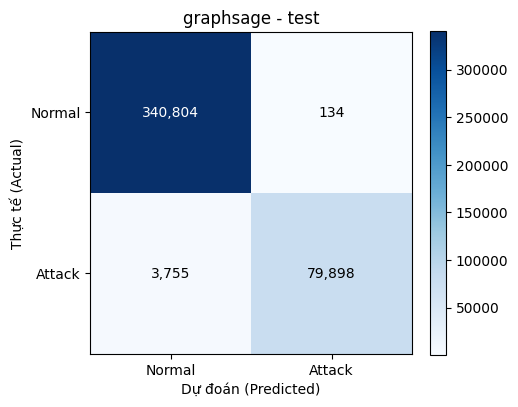

[graphsage_test] F1=0.9762 | Recall=0.9551 | Precision=0.9983 | Macro-F1=0.9853 | FPR=0.0004 | CM(TN,FP,FN,TP)=(340,804, 134, 3,755, 79,898)
>>> Ngưỡng tối ưu của Baseline MLP (chọn trên Val): τ = 0.9


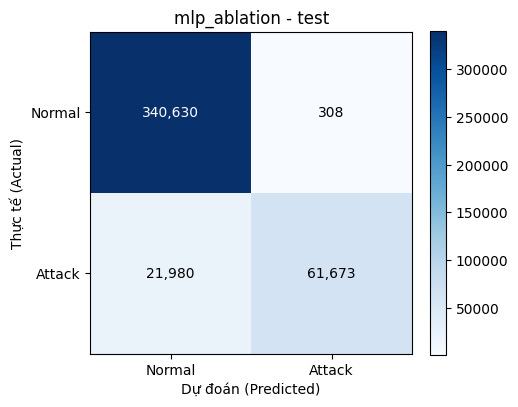

[mlp_ablation_test] F1=0.8470 | Recall=0.7372 | Precision=0.9950 | Macro-F1=0.9076 | FPR=0.0009 | CM(TN,FP,FN,TP)=(340,630, 308, 21,980, 61,673)


,Mô hình,Accuracy,Precision,Recall,F1-Score,Macro-F1,FPR
0,"MLP (Không đồ thị, τ=0.9)",0.9475,0.9950,0.7372,0.8470,0.9076,0.0009
1,"E-GraphSAGE (Có đồ thị, τ=0.5)",0.9908,0.9983,0.9551,0.9762,0.9853,0.0004


In [20]:
import json
import os
import metrics
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader as TorchDataLoader, TensorDataset

# Đảm bảo các thư mục & biến môi trường tồn tại
MODEL_DIR = globals().get("MODEL_DIR", "/kaggle/working/models")
RESULT_DIR = globals().get("RESULT_DIR", "/kaggle/working/results")
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
device = DEVICE

# 1. Lưu kết quả E-GraphSAGE mới nhất qua metrics.py (sắp xếp đồng bộ mergesort như Cell 13)
ts_col = "timestamp" if "timestamp" in meta_te.columns else "Timestamp"
order_te = np.argsort(meta_te[ts_col].to_numpy(), kind="mergesort")
y_true_te_sorted = meta_te["label_bin"].to_numpy()[order_te]
l_multi_te_sorted = meta_te["label_multi"].to_numpy()[order_te]
y_pred_test = final_preds  # Biến dùng tiếp cho Cell 18 (Error Analysis)

metrics.evaluate_and_save(
    model_name="graphsage",
    split_name="test",
    y_true=y_true_te_sorted,
    y_pred=y_pred_test,
    y_score=test_probs,
    label_multi=l_multi_te_sorted,
    out_dir=RESULT_DIR,
)


# 2. Huấn luyện & đánh giá Baseline MLP (Kiểm soát chặt chẽ siêu tham số công bằng với E-GraphSAGE)
class BaselineMLP(nn.Module):
    """Mô hình Ablation: Giữ nguyên kiến trúc phân loại & siêu tham số nhưng bỏ cấu trúc đồ thị"""

    def __init__(self, in_dim, hidden_dim=128, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.LeakyReLU(0.2),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, x):
        x = torch.clamp(x, -25.0, 25.0)
        return self.net(x).squeeze(-1)


tr_ds = TensorDataset(
    torch.tensor(Xtr[final_features].to_numpy(dtype=np.float32)),
    torch.tensor(meta_tr["label_bin"].to_numpy(dtype=np.float32)),
)
va_ds = TensorDataset(
    torch.tensor(Xva[final_features].to_numpy(dtype=np.float32)),
    torch.tensor(meta_va["label_bin"].to_numpy(dtype=np.float32)),
)
te_ds = TensorDataset(
    torch.tensor(Xte[final_features].to_numpy(dtype=np.float32)),
    torch.tensor(meta_te["label_bin"].to_numpy(dtype=np.float32)),
)

tr_tab_loader = TorchDataLoader(tr_ds, batch_size=2048, shuffle=True)
va_tab_loader = TorchDataLoader(va_ds, batch_size=4096, shuffle=False)
te_tab_loader = TorchDataLoader(te_ds, batch_size=4096, shuffle=False)

mlp_model = BaselineMLP(
    in_dim=len(final_features), hidden_dim=128, dropout=0.3
).to(device)
mlp_opt = torch.optim.AdamW(mlp_model.parameters(), lr=1e-3, weight_decay=1e-4)
mlp_sched = torch.optim.lr_scheduler.CosineAnnealingLR(mlp_opt, T_max=15)
mlp_crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([4.0], device=device))

best_mlp_f1 = 0.0
for epoch in range(1, 16):
    mlp_model.train()
    for bx, by in tr_tab_loader:
        bx, by = bx.to(device), by.to(device)
        mlp_opt.zero_grad()
        loss = mlp_crit(mlp_model(bx), by * 0.98 + 0.01)
        loss.backward()
        mlp_opt.step()
    mlp_sched.step()

    mlp_model.eval()
    v_preds, v_trues = [], []
    with torch.no_grad():
        for bx, by in va_tab_loader:
            probs = torch.sigmoid(mlp_model(bx.to(device)))
            v_preds.append((probs >= 0.5).cpu().numpy())
            v_trues.append(by.numpy())
    vf1 = f1_score(np.concatenate(v_trues), np.concatenate(v_preds))
    if vf1 > best_mlp_f1:
        best_mlp_f1 = vf1
        torch.save(mlp_model.state_dict(), f"{MODEL_DIR}/mlp_ablation.pth")

# Chọn ngưỡng tối ưu của MLP trên tập Validation (tránh rò rỉ dữ liệu Test)
mlp_model.load_state_dict(
    torch.load(f"{MODEL_DIR}/mlp_ablation.pth", map_location=device)
)
mlp_model.eval()
val_mlp_probs = []
with torch.no_grad():
    for bx, _ in va_tab_loader:
        val_mlp_probs.append(
            torch.sigmoid(mlp_model(bx.to(device))).cpu().numpy()
        )
val_mlp_probs = np.concatenate(val_mlp_probs)

y_va_arr = meta_va["label_bin"].to_numpy()
thresholds_mlp = np.concatenate(
    [np.arange(0.05, 0.10, 0.02), np.arange(0.10, 0.91, 0.05)]
)
best_mlp_th = float(
    round(
        max(
            thresholds_mlp,
            key=lambda t: f1_score(y_va_arr, (val_mlp_probs >= t).astype(int)),
        ),
        4,
    )
)
print(f">>> Ngưỡng tối ưu của Baseline MLP (chọn trên Val): τ = {best_mlp_th}")

# Đánh giá MLP trên tập Test bằng metrics.py
mlp_probs = []
with torch.no_grad():
    for bx, _ in te_tab_loader:
        mlp_probs.append(torch.sigmoid(mlp_model(bx.to(device))).cpu().numpy())
mlp_probs = np.concatenate(mlp_probs)

y_te_arr = meta_te["label_bin"].to_numpy()
mlp_preds = (mlp_probs >= best_mlp_th).astype(int)

metrics.evaluate_and_save(
    model_name="mlp_ablation",
    split_name="test",
    y_true=y_te_arr,
    y_pred=mlp_preds,
    y_score=mlp_probs,
    label_multi=meta_te["label_multi"].to_numpy(),
    out_dir=RESULT_DIR,
)

# 3. In bảng so sánh Ablation Study
with open(f"{RESULT_DIR}/graphsage_test_metrics.json") as f:
    gnn_res = json.load(f)
with open(f"{RESULT_DIR}/mlp_ablation_test_metrics.json") as f:
    mlp_res = json.load(f)

ablation_df = pd.DataFrame([
    {
        "Mô hình": f"MLP (Không đồ thị, τ={best_mlp_th})",
        "Accuracy": mlp_res["accuracy"],
        "Precision": mlp_res["precision"],
        "Recall": mlp_res["recall"],
        "F1-Score": mlp_res["f1"],
        "Macro-F1": mlp_res["macro_f1"],
        "FPR": mlp_res["fpr"],
    },
    {
        "Mô hình": f"E-GraphSAGE (Có đồ thị, τ={best_thresh})",
        "Accuracy": gnn_res["accuracy"],
        "Precision": gnn_res["precision"],
        "Recall": gnn_res["recall"],
        "F1-Score": gnn_res["f1"],
        "Macro-F1": gnn_res["macro_f1"],
        "FPR": gnn_res["fpr"],
    },
])
ablation_df.to_csv(f"{RESULT_DIR}/ablation_study_comparison.csv", index=False)
display(ablation_df.round(4))

### Cell 18: Error Analysis — Mổ xẻ chi tiết GNN nhận diện sai loại tấn công nào nhất

=== BẢNG PHÂN TÍCH LỖI CHI TIẾT TỪNG LOẠI TẤN CÔNG (BÀN GIAO 3) ===


,Attack_Type,Total_Samples,Detected_Correct,Missed_Errors,Recall_%,Miss_Rate_%
4,DoS Hulk,34661,31333,3328,90.40,9.60
1,Bot,295,0,295,0.00,100.00
0,BENIGN,340938,340804,134,99.96,0.04
5,DoS Slowhttptest,825,700,125,84.85,15.15
9,Infiltration,6,0,6,0.00,100.00
8,Heartbleed,2,1,1,50.00,50.00
2,DDoS,19205,19205,0,100.00,0.00
6,DoS slowloris,870,870,0,100.00,0.00
3,DoS GoldenEye,1544,1544,0,100.00,0.00
7,FTP-Patator,1191,1191,0,100.00,0.00


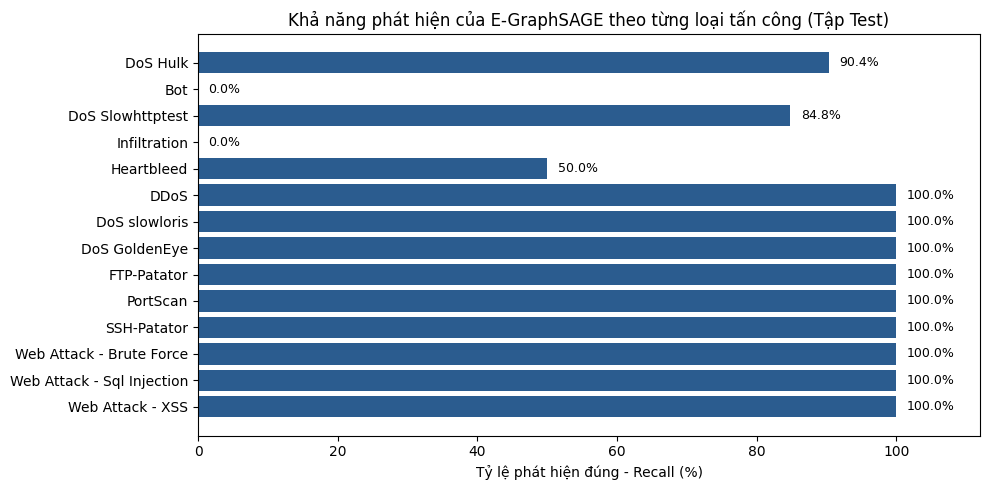

In [22]:
import matplotlib.pyplot as plt
m_te = pd.DataFrame({
    "label_bin": y_true_te_sorted,
    "label_multi": l_multi_te_sorted,
})
# Tính trực tiếp tỷ lệ phát hiện & bỏ sót trên từng loại tấn công từ y_pred_test
df_eval = pd.DataFrame({
    "Attack_Type": m_te["label_multi"].astype(str).to_numpy(),
    "y_true": m_te["label_bin"].to_numpy(),
    "y_pred": y_pred_test
})

rows = []
for atk_type, grp in df_eval.groupby("Attack_Type"):
    total = len(grp)
    if atk_type == "BENIGN":
        correct = (grp["y_pred"] == 0).sum()
        missed = (grp["y_pred"] == 1).sum()  # False Positives cho BENIGN
    else:
        correct = (grp["y_pred"] == 1).sum()  # True Positives
        missed = (grp["y_pred"] == 0).sum()   # False Negatives (bỏ sót)
    recall = correct / total if total > 0 else 0.0
    rows.append({
        "Attack_Type": atk_type,
        "Total_Samples": total,
        "Detected_Correct": correct,
        "Missed_Errors": missed,
        "Recall_%": round(recall * 100, 2),
        "Miss_Rate_%": round((1 - recall) * 100, 2)
    })

err_sorted = pd.DataFrame(rows).sort_values(by="Missed_Errors", ascending=False)
err_sorted.to_csv(f"{RESULT_DIR}/error_analysis_summary.csv", index=False)

print("=== BẢNG PHÂN TÍCH LỖI CHI TIẾT TỪNG LOẠI TẤN CÔNG (BÀN GIAO 3) ===")
display(err_sorted)

# Vẽ biểu đồ tỷ lệ phát hiện (Recall) theo từng loại tấn công (loại bỏ BENIGN)
attack_only = err_sorted[err_sorted["Attack_Type"] != "BENIGN"].copy()

plt.figure(figsize=(10, 5))
bars = plt.barh(attack_only["Attack_Type"], attack_only["Recall_%"], color="#2b5c8f")
plt.xlabel("Tỷ lệ phát hiện đúng - Recall (%)")
plt.title("Khả năng phát hiện của E-GraphSAGE theo từng loại tấn công (Tập Test)")
plt.xlim(0, 112)
plt.gca().invert_yaxis()
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1.5, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/error_analysis_chart.png", dpi=300)
plt.show()

### Cell 19: Trực quan hóa Đồ thị Mạng (NetworkX) để dán vào Báo cáo

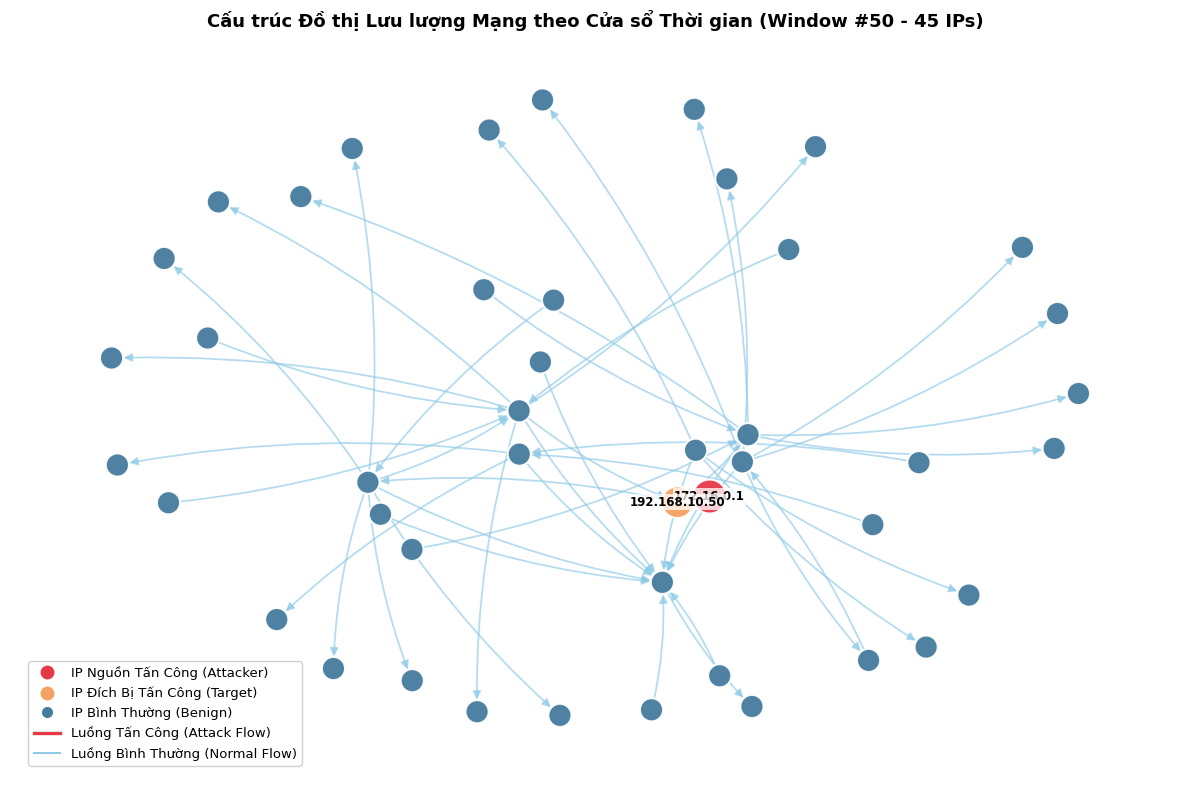

In [24]:
import networkx as nx
from matplotlib.lines import Line2D
# Lấy đầy đủ các cột thông tin mạng của tập Test từ biến meta có sẵn
m_te = meta.copy()
if "Timestamp" in m_te.columns and "timestamp" not in m_te.columns:
    m_te["timestamp"] = m_te["Timestamp"]
if "Source IP" in m_te.columns and "src_ip" not in m_te.columns:
    m_te["src_ip"] = m_te["Source IP"]
if "Destination IP" in m_te.columns and "dst_ip" not in m_te.columns:
    m_te["dst_ip"] = m_te["Destination IP"]
m_te["label_bin"] = np.asarray(yte)
m_te["label_multi"] = np.asarray(lte)
# 1. Tìm cửa sổ có nhiều IP nhất mà vẫn có cả Attack lẫn Normal
best_win_idx = 0
best_score = -1
for idx, g in enumerate(test_graphs):
    atk_ratio = g.y.mean().item()
    n_nodes = g.num_nodes
    if 0.01 <= atk_ratio <= 0.85 and n_nodes >= 10:
        if n_nodes > best_score:
            best_score = n_nodes
            best_win_idx = idx

order = np.argsort(m_te["timestamp"].to_numpy())
start = best_win_idx * WINDOW_SIZE
win_meta = m_te.iloc[order[start : start + WINDOW_SIZE]]

# 2. Lấy toàn bộ các dòng Attack + tối đa 150 dòng Normal ngẫu nhiên trong cửa sổ đó
atk_rows = win_meta[win_meta["label_bin"] == 1]
norm_rows = win_meta[win_meta["label_bin"] == 0].sample(
    n=min(150, (win_meta["label_bin"] == 0).sum()), random_state=42
)
sub_meta = pd.concat([atk_rows, norm_rows])

G = nx.DiGraph()
attack_nodes, victim_nodes = set(), set()

for _, row in sub_meta.iterrows():
    u, v = str(row["src_ip"]), str(row["dst_ip"])
    if u == v:
        continue
    is_atk = int(row["label_bin"]) == 1
    if is_atk:
        attack_nodes.add(u)
        victim_nodes.add(v)
    if G.has_edge(u, v):
        G[u][v]["weight"] += 1
        G[u][v]["is_atk"] = G[u][v]["is_atk"] or is_atk
    else:
        G.add_edge(u, v, weight=1, is_atk=is_atk)

# Giới hạn tối đa 45 nút để hình không bị rối chữ
if G.number_of_nodes() > 45:
    important_nodes = list(attack_nodes | victim_nodes)
    other_nodes = [n for n in G.nodes() if n not in important_nodes]
    keep_nodes = important_nodes + other_nodes[: max(0, 45 - len(important_nodes))]
    G = G.subgraph(keep_nodes).copy()

plt.figure(figsize=(12, 8))
# Dùng spring_layout với khoảng cách k lớn hơn để các cụm nút bung đều khắp khung hình
pos = nx.spring_layout(G, k=1.2, iterations=80, seed=42)

node_colors, node_sizes = [], []
for n in G.nodes():
    if n in attack_nodes:
        node_colors.append("#e63946")   # Đỏ: IP nguồn tấn công
        node_sizes.append(600)
    elif n in victim_nodes:
        node_colors.append("#f4a261")   # Cam: IP mục tiêu bị tấn công
        node_sizes.append(520)
    else:
        node_colors.append("#457b9d")   # Xanh dương: IP bình thường
        node_sizes.append(280)

atk_edges = [(u, v) for u, v, d in G.edges(data=True) if d["is_atk"]]
norm_edges = [(u, v) for u, v, d in G.edges(data=True) if not d["is_atk"]]

nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, alpha=0.95, edgecolors="white", linewidths=1.5)
nx.draw_networkx_edges(G, pos, edgelist=norm_edges, edge_color="#8ecae6", alpha=0.65, width=1.3, arrows=True, arrowsize=12, connectionstyle="arc3,rad=0.08")
nx.draw_networkx_edges(G, pos, edgelist=atk_edges, edge_color="#e63946", alpha=0.95, width=2.4, arrows=True, arrowsize=16, connectionstyle="arc3,rad=0.08")

labels = {n: n for n in G.nodes() if (n in attack_nodes or n in victim_nodes)}
nx.draw_networkx_labels(
    G, pos, labels=labels, font_size=8.5, font_weight="bold",
    bbox=dict(facecolor="white", alpha=0.75, edgecolor="none", pad=1.2)
)

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='IP Nguồn Tấn Công (Attacker)', markerfacecolor='#e63946', markersize=11),
    Line2D([0], [0], marker='o', color='w', label='IP Đích Bị Tấn Công (Target)', markerfacecolor='#f4a261', markersize=11),
    Line2D([0], [0], marker='o', color='w', label='IP Bình Thường (Benign)', markerfacecolor='#457b9d', markersize=9),
    Line2D([0], [0], color='#e63946', lw=2.4, label='Luồng Tấn Công (Attack Flow)'),
    Line2D([0], [0], color='#8ecae6', lw=1.5, label='Luồng Bình Thường (Normal Flow)')
]
plt.legend(handles=legend_elements, loc="lower left", bbox_to_anchor=(0.01, 0.01), frameon=True, facecolor="white", framealpha=0.9, fontsize=9.5)
plt.title(f"Cấu trúc Đồ thị Lưu lượng Mạng theo Cửa sổ Thời gian (Window #{best_win_idx} - {G.number_of_nodes()} IPs)", fontsize=13, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/network_graph_visualization.png", dpi=300)
plt.show()

In [25]:
!zip -r /kaggle/working/results_final.zip /kaggle/working/results/

  adding: kaggle/working/results/ (stored 0%)
  adding: kaggle/working/results/graphsage_test_metrics.json (deflated 47%)
  adding: kaggle/working/results/error_analysis_summary.csv (deflated 44%)
  adding: kaggle/working/results/error_analysis_chart.png (deflated 23%)
  adding: kaggle/working/results/graphsage_test_detection_by_type.csv (deflated 40%)
  adding: kaggle/working/results/mlp_ablation_test_confusion_matrix.png (deflated 15%)
  adding: kaggle/working/results/mlp_ablation_test_metrics.json (deflated 47%)
  adding: kaggle/working/results/ablation_study_comparison.csv (deflated 26%)
  adding: kaggle/working/results/mlp_ablation_test_detection_by_type.csv (deflated 37%)
  adding: kaggle/working/results/graphsage_test_confusion_matrix.png (deflated 17%)
  adding: kaggle/working/results/network_graph_visualization.png (deflated 6%)


In [23]:
assert (
    meta_te["label_bin"].to_numpy()
    == pd.read_parquet(f"{DATA_DIR}/test_meta.parquet")["label_bin"].to_numpy()
).all()
print("Xác nhận dữ liệu Test khớp 100% với bản gốc của Khang!")

Xác nhận dữ liệu Test khớp 100% với bản gốc của Khang!


In [31]:
import os
import re
import shutil

# 1. Đảm bảo export_bundle/checkpoint.pth là bản gốc từ models/checkpoint.pth (giữ nguyên state_dict gốc)
shutil.copy("/kaggle/working/models/checkpoint.pth", "export_bundle/checkpoint.pth")

# 2. Cập nhật chỉ duy nhất đoạn chống lỗi NaN/Infinity trong export_bundle/predict_window.py gốc
# (Ưu tiên đọc từ /kaggle/working/predict_window.py gốc nếu có, hoặc sửa trực tiếp trên export_bundle/predict_window.py)
src_py = "/kaggle/working/predict_window.py" if os.path.exists("/kaggle/working/predict_window.py") else "export_bundle/predict_window.py"
with open(src_py, "r", encoding="utf-8") as f:
    code = f.read()

old_block = """X = df[self.feature_cols].replace([np.inf, -np.inf], np.nan)
        X = X.fillna(self.medians).astype(np.float32)"""

new_block = """X = df[self.feature_cols].apply(pd.to_numeric, errors="coerce")
        X = X.replace([np.inf, -np.inf], np.nan).fillna(self.medians).astype(np.float32)
        X = X.replace([np.inf, -np.inf], np.nan).fillna(self.medians).astype(np.float32)"""

if old_block in code:
    code = code.replace(old_block, new_block)
else:
    # Dự phòng trường hợp thụt lề khác
    code = re.sub(
        r"X\s*=\s*df\[self\.feature_cols\]\.replace\(\[np\.inf,\s*-np\.inf\],\s*np\.nan\)\s*\n\s*X\s*=\s*X\.fillna\(self\.medians\)\.astype\(np\.float32\)",
        new_block,
        code,
    )

with open("export_bundle/predict_window.py", "w", encoding="utf-8") as f:
    f.write(code)

# 3. Gộp thư mục results/ vào export_bundle/results/ và nén duy nhất 1 lần
if os.path.exists("/kaggle/working/results"):
    shutil.copytree("/kaggle/working/results", "export_bundle/results", dirs_exist_ok=True)

if os.path.exists("/kaggle/working/kimngan.zip"):
    os.remove("/kaggle/working/kimngan.zip")

shutil.make_archive("/kaggle/working/kimngan", "zip", "export_bundle")
print("HOÀN TẤT ĐÓNG GÓI! File sẵn sàng tải về: /kaggle/working/kimngan.zip")
print("Các mục bên trong kimngan.zip:", os.listdir("export_bundle"))

HOÀN TẤT ĐÓNG GÓI! File sẵn sàng tải về: /kaggle/working/kimngan.zip
Các mục bên trong kimngan.zip: ['medians.joblib', 'checkpoint.pth', 'metadata.json', 'results', 'predict_window.py', 'scaler.joblib']
